In [2]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
conn = sqlite3.connect("flight_delays.db")

In [3]:
query = """
SELECT
    COUNT(*) AS total_flights,
    ROUND(100.0 * SUM(CASE WHEN ArrDelay <= 15 THEN 1 ELSE 0 END) / COUNT(*), 2) AS otp_percentage,
    ROUND(100.0 * SUM(CASE WHEN ArrDelay > 15 THEN 1 ELSE 0 END) / COUNT(*), 2) AS delay_rate_percentage
FROM flight_info;
"""

delay_metrics = pd.read_sql_query(query, conn)
print(delay_metrics)

   total_flights  otp_percentage  delay_rate_percentage
0        7001619           77.01                  21.25


In [ ]:
-- This version filtered out valid, complete flights and strictly checks for less than 15 minutes (ArrDelay < 15), excluding flights delayed by exactly 15 minutes
query = """
SELECT
    COUNT(*) AS completed_flights,
    ROUND(100.0 * SUM(CASE WHEN ArrDelay < 15 THEN 1 ELSE 0 END) / COUNT(*), 2) AS otp_percentage
FROM flight_info
WHERE Cancelled = 0
  AND Diverted = 0
  AND ArrDelay IS NOT NULL;
"""
print(pd.read_sql_query(query, conn))

   completed_flights  otp_percentage
0            6879484           77.69


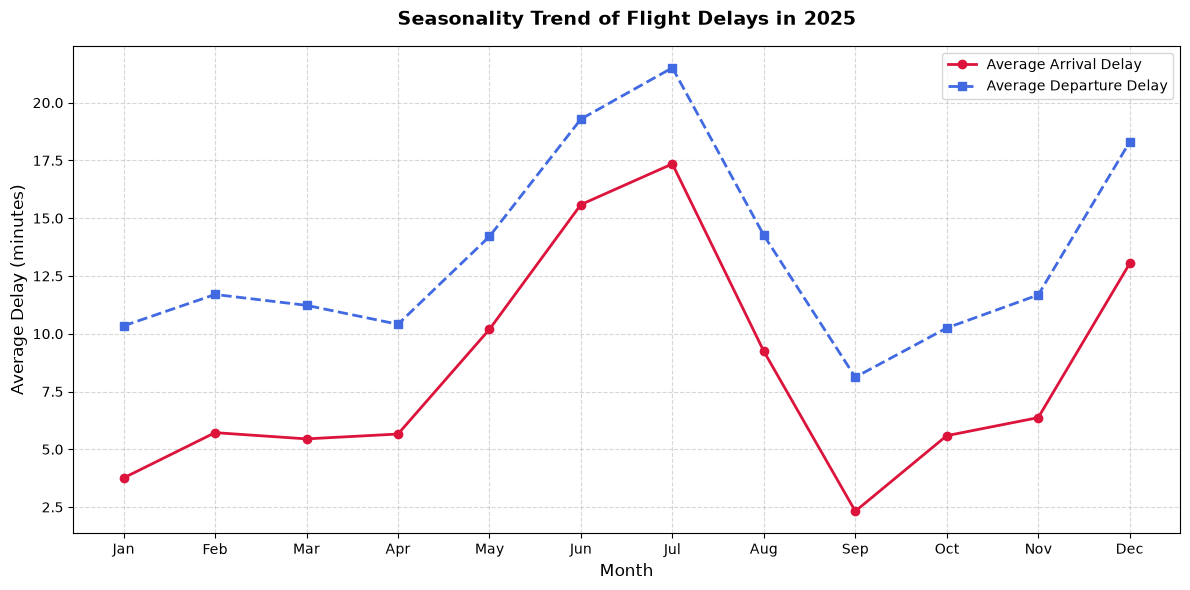

In [5]:
query_carrier = """
SELECT
    Month, 
    COUNT(*) AS total_flights,
    ROUND(AVG(ArrDelay), 2) AS avg_arrival_delay,
    ROUND(AVG(DepDelay), 2) AS avg_departure_delay
FROM flight_info
GROUP BY Month
ORDER BY Month ASC;
"""

df_carrier = pd.read_sql_query(query_carrier, conn)
conn.close()

# Making a clean plot for visualizing monthly seasonality of flight delays
plt.figure(figsize=(12, 6))

plt.plot(df_carrier['Month'], df_carrier['avg_arrival_delay'], marker='o', label='Average Arrival Delay', color='crimson', linewidth=2)
plt.plot(df_carrier['Month'], df_carrier['avg_departure_delay'], marker='s', label='Average Departure Delay', color='royalblue', linewidth=2, linestyle='--')

plt.title('Seasonality Trend of Flight Delays in 2025', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=12)
plt.ylabel('Average Delay (minutes)', fontsize=12)

month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
plt.xticks(df_carrier['Month'], month_labels)

plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()


In [6]:
conn = sqlite3.connect("flight_delays.db")

# Buffer Recovery rate -> How often airlines recover from delays and arrive on time after a delay. To make up for the time lost after a late departure.

query_buffer_recovery = """
SELECT
    Reporting_Airline AS Carrier,
    COUNT(*) AS total_flights,
    ROUND(100.0 * SUM(CASE WHEN DepDelay > ArrDelay THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_made_up_time
FROM flight_info
WHERE DepDelay > 0
GROUP BY Carrier
ORDER BY pct_made_up_time DESC;
"""

df_buffer_recovery = pd.read_sql_query(query_buffer_recovery, conn)
display(df_buffer_recovery)

,Carrier,total_flights,pct_made_up_time
0,WN,676986,78.04
1,NK,66243,71.73
2,DL,346636,70.49
3,F9,76564,68.80
4,AA,388488,68.64
5,UA,278751,67.89
6,B6,90609,67.62
7,OO,239785,64.44
8,AS,96925,63.71
9,OH,89976,63.52


In [7]:
# Exploring severe disruption (extreme outliers) in flight delays. Extreme outliers are flights that are delayed by more than 60 or 120 minutes, which are compared to minor inconveniences. 

severe_disruption = """
SELECT
    Origin,
    COUNT(*) AS total_departures,
    SUM(CASE WHEN ArrDelay >= 60 THEN 1 ELSE 0 END) AS severe_delays_1h,
    ROUND(100.0 * SUM(CASE WHEN ArrDelay >= 60 THEN 1 ELSE 0 END) / COUNT(*), 2) AS severe_delay_rate_pct
FROM flight_info
GROUP BY Origin
HAVING total_departures > 500
ORDER BY severe_delay_rate_pct DESC
LIMIT 15;
"""

df_severe_disruption = pd.read_sql_query(severe_disruption, conn)
display(df_severe_disruption)

,Origin,total_departures,severe_delays_1h,severe_delay_rate_pct
0,USA,710,144,20.28
1,HTS,540,98,18.15
2,SUX,729,123,16.87
3,ASE,7685,1268,16.50
4,JLN,726,119,16.39
5,JST,727,111,15.27
6,DVL,652,92,14.11
7,MGM,2113,297,14.06
8,SCK,564,79,14.01
9,ROA,1772,244,13.77


In [8]:
# Now measuring the performance gap between high-traffic hours and low-traffic hours (Peak vs Off-Peak). This analysis will help us understand how flight delays vary based on the time of day, which can be crucial for scheduling and operational efficiency.

performance_gap = """
SELECT
    CASE 
        WHEN Deptime BETWEEN 600 AND 959 THEN 'Morning Rush'
        WHEN Deptime BETWEEN 1600 AND 1959 THEN 'Evening Rush'
        ELSE 'Off-Peak'
    END AS Time_bucket,
    COUNT(*) AS flight_volume, 
    ROUND(AVG(DepDelay), 2) AS avg_departure_delay
FROM flight_info
GROUP BY Time_bucket
ORDER BY flight_volume DESC;
"""

df_performance_gap = pd.read_sql_query(performance_gap, conn)
display(df_performance_gap)

,Time_bucket,flight_volume,avg_departure_delay
0,Off-Peak,3742674,16.50
1,Morning Rush,1687937,3.10
2,Evening Rush,1571008,17.98


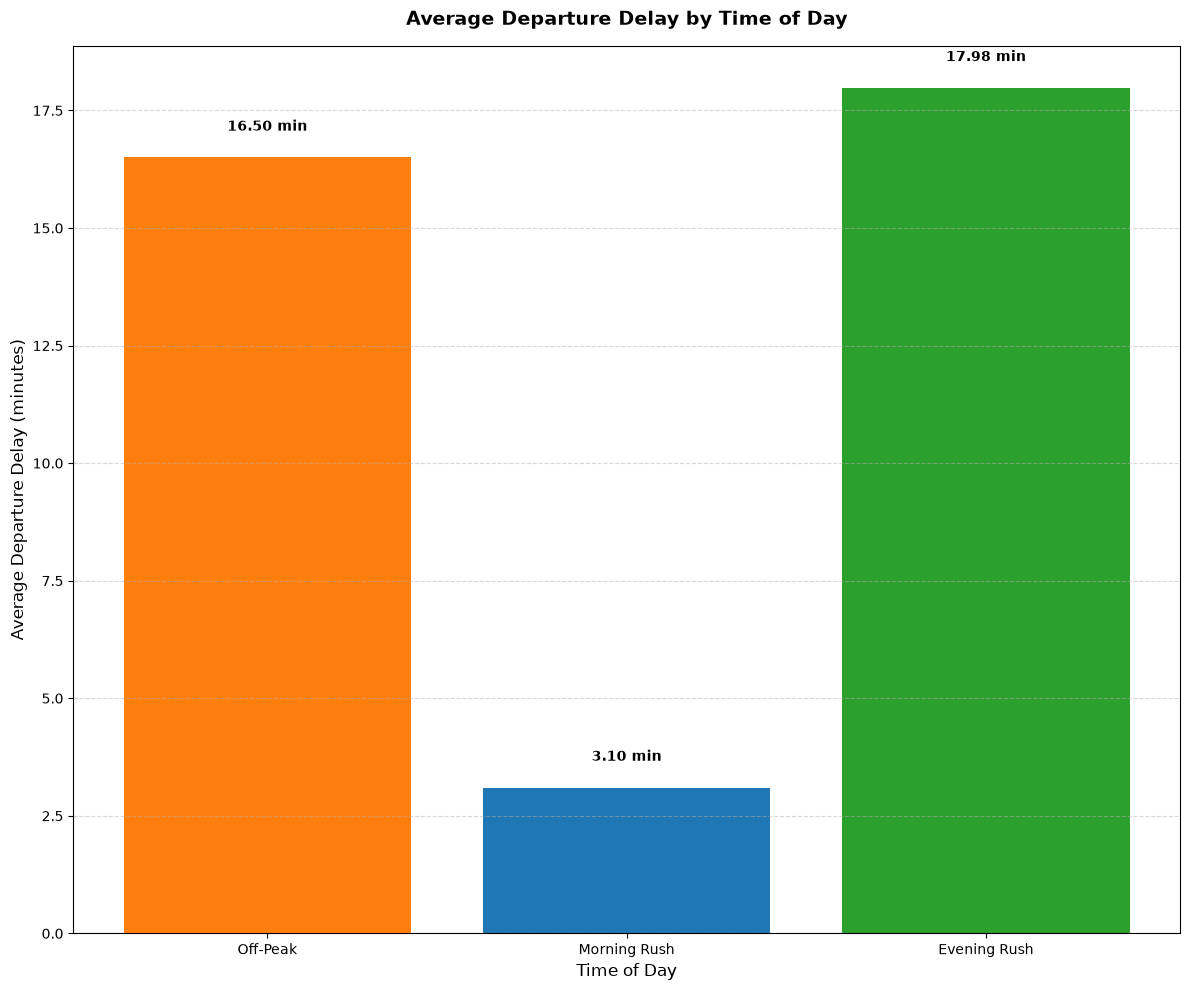

In [9]:
conn.close()

# Bar chart for visualizing the performance gap between high-traffic hours and low-traffic hours (Peak vs Off-Peak)
plt.figure(figsize=(12, 10))
bars = plt.bar(df_performance_gap['Time_bucket'], df_performance_gap['avg_departure_delay'], color=['#ff7f0e', '#1f77b4', '#2ca02c'])

plt.title('Average Departure Delay by Time of Day', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Time of Day', fontsize=12)
plt.ylabel('Average Departure Delay (minutes)', fontsize=12)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.5, f'{height:.2f} min', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [10]:
conn = sqlite3.connect("flight_delays.db")

# Running day of week analysis to understand how flight delays vary based on the day of the week. This can help identify patterns and trends that may be influenced by factors such as passenger volume, weather conditions, and operational constraints.

day_of_week_analysis = """
    SELECT
        CASE DayofWeek
            WHEN 1 THEN 'Mon'
            WHEN 2 THEN 'Tue'
            WHEN 3 THEN 'Wed'
            WHEN 4 THEN 'Thu'
            WHEN 5 THEN 'Fri'
            WHEN 6 THEN 'Sat'
            WHEN 7 THEN 'Sun'
        END AS DayLabel,
        COUNT(*) AS total_flights,
        ROUND(AVG(ArrDelay), 2) AS avg_arrival_delay,
        ROUND(AVG(DepDelay), 2) AS avg_departure_delay,
        ROUND(100.0 * SUM(CASE WHEN ArrDelay > 15 THEN 1 ELSE 0 END) / COUNT(*), 2) AS delay_rate
    FROM flight_info
    GROUP BY DayofWeek
    ORDER BY DayofWeek ASC;
"""

df_day_of_week = pd.read_sql_query(day_of_week_analysis, conn)
display(df_day_of_week)


,DayLabel,total_flights,avg_arrival_delay,avg_departure_delay,delay_rate
0,Mon,1050150,10.15,15.24,22.67
1,Tue,945648,4.11,9.85,17.53
2,Wed,966102,5.00,10.23,18.38
3,Thu,1040825,9.55,14.05,22.17
4,Fri,1044333,9.49,14.24,22.11
5,Sat,906399,6.91,12.70,20.01
6,Sun,1048162,13.45,17.88,25.11


In [11]:
# Delay root cause breakdown by airline. This is important because it helps identify who is responsible for what (Carrier vs. Weather vs. NAS vs. Security vs. Late Aircraft). This analysis can help airlines and regulators understand the primary contributors to flight delays and develop strategies to mitigate them.

delay_root_cause = """
SELECT
    Reporting_Airline AS Carrier,
    COUNT(*) AS total_flights,
    ROUND(AVG(CarrierDelay), 2) AS avg_carrier_delay,
    ROUND(AVG(WeatherDelay), 2) AS avg_weather_delay,
    ROUND(AVG(NASDelay), 2) AS avg_nas_delay,
    ROUND(AVG(SecurityDelay), 2) AS avg_security_delay,
    ROUND(AVG(LateAircraftDelay), 2) AS avg_late_aircraft_delay
FROM flight_info
GROUP BY Carrier
ORDER BY total_flights DESC;
"""

df_delay_root_cause = pd.read_sql_query(delay_root_cause, conn)

delay_cols = ['avg_carrier_delay', 'avg_weather_delay', 'avg_nas_delay', 'avg_security_delay', 'avg_late_aircraft_delay']

display(df_delay_root_cause.style.background_gradient(
    subset=delay_cols, cmap='YlOrRd'
)
)

,Carrier,total_flights,avg_carrier_delay,avg_weather_delay,avg_nas_delay,avg_security_delay,avg_late_aircraft_delay
0,WN,1391885,14.940000,1.680000,11.010000,0.130000,29.200000
1,DL,1026332,31.360000,3.700000,15.560000,0.050000,22.600000
2,AA,973653,27.210000,4.940000,12.960000,0.100000,38.090000
3,OO,839821,39.880000,11.920000,14.990000,0.100000,16.930000
4,UA,795271,18.600000,3.740000,23.700000,0.000000,26.490000
5,YX,346036,16.700000,4.120000,24.690000,0.050000,26.300000
6,MQ,299322,12.870000,7.480000,15.200000,0.070000,27.670000
7,OH,248735,26.130000,6.770000,12.180000,0.130000,45.850000
8,AS,245588,14.240000,1.790000,14.670000,0.250000,20.420000
9,B6,231413,20.680000,2.040000,21.450000,0.120000,31.840000


In [12]:
# Now goal is to identify the top 20 worst origin-destination routes in the entire US based on the total delayed minutes.

worst_origin_destination_routes = """
SELECT
    Origin || '->' || Dest AS route,
    COUNT(*) AS total_flights,
    ROUND(AVG(ArrDelay), 2) AS avg_arrival_delay,
    SUM(CASE WHEN ArrDelay > 15 THEN ArrDelay ELSE 0 END) AS delayed_flights
FROM flight_info
GROUP BY origin, dest
HAVING total_flights >= 500
ORDER BY avg_arrival_delay DESC
LIMIT 20;
"""

df_worst_routes = pd.read_sql_query(worst_origin_destination_routes, conn)
display(df_worst_routes)


,route,total_flights,avg_arrival_delay,delayed_flights
0,PNS->DCA,932,41.02,42665.0
1,JAC->DFW,761,36.08,31706.0
2,ASE->IAH,547,35.44,21572.0
3,DFW->HNL,567,34.42,23618.0
4,EYW->PHL,530,33.28,20296.0
5,ASE->ORD,958,32.85,36276.0
6,ASE->DFW,1178,32.44,43711.0
7,DFW->BUF,538,32.42,18655.0
8,MIA->MEM,540,32.06,19299.0
9,HPN->DCA,1359,31.82,49120.0
